# Optimization and regularization on noisy image features

How do dropout and weight decay change the training-validation gap?

I train matched MLPs on digit pixels with appended nuisance features. The nuisance variables make overfitting visible while preserving the label task. The notebook records loss, gradient scale and validation checkpoint selection.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import json
import os
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from deep_projects.training import (
    DataSplit,
    Trainer,
    TrainConfig,
    classification_scores,
    digits_data,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "02_optimization_and_regularization"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Training-only feature scaling

Noise features carry no class information by construction. They are generated independently for all images before splitting. StandardScaler learns their scale from training observations only. The test set retains the same generating distribution.

In [5]:
from sklearn.preprocessing import StandardScaler

base = digits_data(8)
rng = np.random.default_rng(1031)
features = []
for dataset in [base.train, base.validation, base.test]:
    pixels, labels = dataset.tensors
    nuisance = rng.normal(size=(len(pixels), 64))
    features.append((np.column_stack([pixels.flatten(1).numpy(), nuisance]), labels))
scaler = StandardScaler().fit(features[0][0])
data = DataSplit(
    *(
        TensorDataset(
            torch.tensor(scaler.transform(values), dtype=torch.float32), labels
        )
        for values, labels in features
    )
)
train_loader, validation_loader, test_loader = data.loaders()
print(data.train.tensors[0].shape)

torch.Size([1077, 128])


## Fixed model family

The hidden layers are identical across runs. Dropout is active only in training mode; weight decay is configured in AdamW. Each experiment starts from the same seed and uses the same minibatch order, so the comparison has fewer incidental differences.

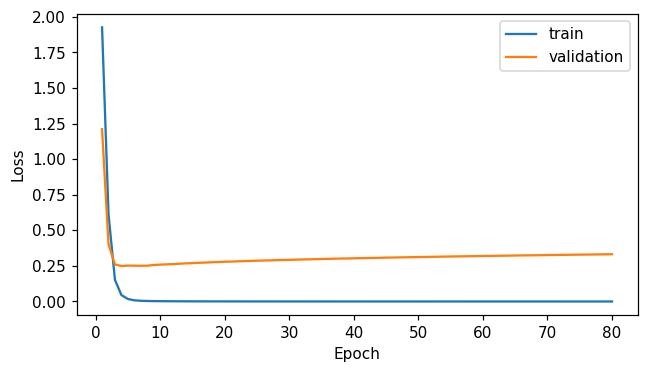

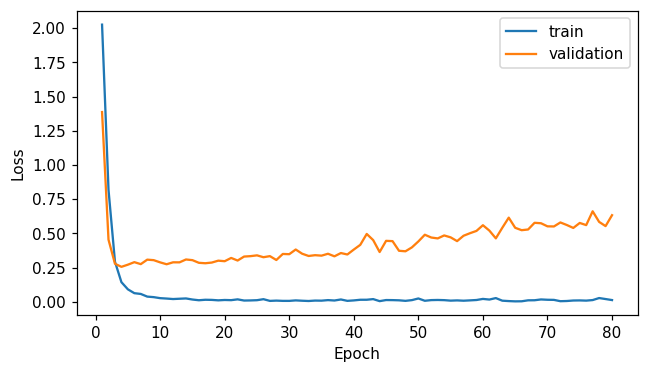

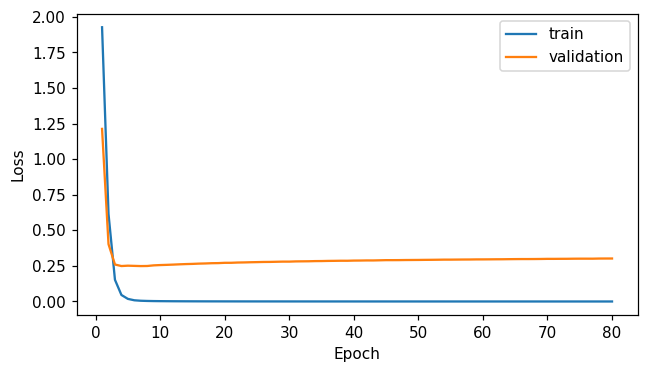

      condition  accuracy  macro_f1       nll  weight_norm
0         plain  0.911111  0.909284  0.249641    12.650658
1       dropout  0.913889  0.912402  0.255319    12.260233
2  weight_decay  0.933333  0.933188  0.248932    13.124969


In [7]:
def build_mlp(dropout):
    return nn.Sequential(
        nn.Linear(128, 128),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10),
    )


conditions = [("plain", 0.0, 0.0), ("dropout", 0.4, 0.0), ("weight_decay", 0.0, 0.03)]
trained, validation_rows = {}, []
for name, dropout, decay in conditions:
    seed_everything()
    model = build_mlp(dropout)
    train_loader, validation_loader, test_loader = data.loaders()
    trainer = Trainer(
        model, nn.CrossEntropyLoss(), TrainConfig(epochs=EPOCHS * 2, weight_decay=decay)
    )
    history = trainer.fit(train_loader, validation_loader)
    plot_history(history, output / f"{name}_loss.png")
    logits, targets = predict(model, validation_loader)
    validation_rows.append(
        {
            "condition": name,
            **classification_scores(logits, targets),
            "weight_norm": float(
                torch.cat([p.detach().flatten() for p in model.parameters()]).norm()
            ),
        }
    )
    trained[name] = model
print(pd.DataFrame(validation_rows))

## Gradient and dropout checks

A finite gradient norm checks the numerical path before an optimizer update. Evaluation mode makes dropout deterministic. The dropout example deliberately compares training and evaluation on the same fixed input.

In [9]:
selected = min(validation_rows, key=lambda row: row["nll"])["condition"]
model = trained[selected]
images, labels = next(iter(train_loader))
model.train()
model.zero_grad(set_to_none=True)
loss = F.cross_entropy(model(images), labels)
loss.backward()
gradient_norm = float(
    torch.sqrt(
        sum(p.grad.square().sum() for p in model.parameters() if p.grad is not None)
    )
)
assert np.isfinite(gradient_norm)
dropout_model = trained["dropout"]
dropout_model.eval()
with torch.inference_mode():
    assert torch.equal(dropout_model(images), dropout_model(images))
model.eval()
logits, targets = predict(model, test_loader)
results = {
    "validation": validation_rows,
    "selected": selected,
    "gradient_norm": gradient_norm,
    "test": classification_scores(logits, targets),
}
print(results)

{'validation': [{'condition': 'plain', 'accuracy': 0.9111111111111111, 'macro_f1': 0.9092843195501021, 'nll': 0.2496405917667074, 'weight_norm': 12.650657653808594}, {'condition': 'dropout', 'accuracy': 0.9138888888888889, 'macro_f1': 0.912401813080632, 'nll': 0.2553190366741296, 'weight_norm': 12.260232925415039}, {'condition': 'weight_decay', 'accuracy': 0.9333333333333333, 'macro_f1': 0.9331878062125535, 'nll': 0.24893214077310766, 'weight_norm': 13.124968528747559}], 'selected': 'weight_decay', 'gradient_norm': 0.03109722211956978, 'test': {'accuracy': 0.9333333333333333, 'macro_f1': 0.9329584619869882, 'nll': 0.17571441880069366}}


## Reading the result

The lowest validation loss selects one condition. Weight norm is descriptive and is affected by architecture and parameterization. A smaller training-validation gap can result from better generalization or from underfitting, so read both losses.

In [11]:
result_path = root / "results" / "02_optimization_and_regularization.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/02_optimization_and_regularization.json


## Next experiment

Compare SGD with momentum to AdamW at validation-selected learning rates. Keep nuisance features and data identities fixed, then repeat over seeds.

## Sources

[HSE deep learning course](https://github.com/mryab/dl-hse-ami) and its [wiki syllabus](https://wiki.cs.hse.ru/Глубинное_обучение_2022). week04_training. UniPd Machine Learning for Human Data: uploaded Lab_nn and Labs 1 to 7, plus the [course data folder](https://drive.google.com/drive/folders/14xwb6leBeD3QMZH6wnnIIOi63D1D8xmS). Lab_nn.

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.